# 04 · MPC：先想象未来，再执行一步

目前已经会用 LQR 控制小车，也会估计看不见的速度。现在把任务改成：推力不能超过 ±1 N，速度不能超过 ±0.8 m/s，位置不能超过 1.05 m。

**核心问题：** 当前的位置还没有越界，当前速度也不超标，但继续这样走是否已经来不及刹车？

**学习成果：** 写出有限时域优化、把它变成凸二次规划、实现滚动控制；用数值实验连接 LQR 与 MPC；识别不可行与软约束的含义。


[00 学习地图与小车建模](00_学习地图与小车建模.ipynb) · [01 经典控制与PID](01_经典控制与PID.ipynb) · [02 状态空间与LQR](02_状态空间与LQR.ipynb) · [03 观测器与Kalman滤波](03_观测器与Kalman滤波.ipynb) · [04 从有限时域优化到MPC](04_从有限时域优化到MPC.ipynb) · [05 综合实验与进阶路线](05_综合实验与进阶路线.ipynb)

每篇可独立运行；本篇内按顺序执行。图中英文标签对应正文中文术语，避免依赖本机中文字体。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, linalg

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 3.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2})
DT = 0.1
MASS, DRAG = 1.0, 0.4
C = np.array([[1.0, 0.0]])

def model(mass=MASS, drag=DRAG):
    Ac = np.array([[0.0, 1.0], [0.0, -drag / mass]])
    Bc = np.array([[0.0], [1.0 / mass]])
    A, B, _, _, _ = signal.cont2discrete((Ac, Bc, C, np.zeros((1, 1))), DT)
    return A, B

A, B = model()
b = B[:, 0]
REF = np.array([1.0, 0.0])

def rollout(policy, steps=120, x0=(0.0, 0.0), disturbance=None, plant=None):
    Ap, Bp = (A, B) if plant is None else plant
    xs, us = [np.array(x0, dtype=float)], []
    for k in range(steps):
        u = float(policy(xs[-1].copy(), k))
        d = 0.0 if disturbance is None else float(disturbance(k))
        xs.append(Ap @ xs[-1] + Bp[:, 0] * (u + d))
        us.append(u)
    return np.asarray(xs), np.asarray(us)

def plot_runs(runs, title, wall=None):
    fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
    for label, (xs, us) in runs.items():
        axes[0].plot(np.arange(len(xs))*DT, xs[:, 0], label=label)
        axes[1].plot(np.arange(len(xs))*DT, xs[:, 1], label=label)
        axes[2].step(np.arange(len(us))*DT, us, where="post", label=label)
    axes[0].axhline(REF[0], color="black", ls=":", label="target")
    if wall is not None:
        axes[0].axhline(wall, color="firebrick", ls="--", label="position limit")
    for ax, label in zip(axes, ["position [m]", "velocity [m/s]", "force [N]"]):
        ax.set_ylabel(label)
    axes[0].legend(ncol=3, fontsize=8)
    axes[-1].set_xlabel("time [s]")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


In [2]:
Q = np.diag([20.0, 2.0])
R = np.array([[0.5]])
P = linalg.solve_discrete_are(A, B, Q, R)
K = np.linalg.solve(R + B.T @ P @ B, B.T @ P @ A)


## 1. 为什么只把 LQR 输出截断不够？

截断修正的是**当前力**，没有重新规划因推力不足而改变的后续轨迹。减速本身需要时间和距离。无阻力近似下，速度 v、最大制动力 $u_{\max}$ 对应的最短停车距离：

$$d_{\mathrm{stop}}\approx\frac{mv^2}{2u_{\max}}.$$

本例阻力在向前运动时帮助刹车，所以这是忽略阻力的直觉估算；准确预测使用 A、B。约束与动力学共同决定能否安全停靠，算法不能绕过物理能力。

MPC（Model Predictive Control，模型预测控制）把未来状态和输入一起优化。它不一定需要深度学习；本篇是线性模型、凸二次代价、线性约束，因此每步解一个凸 QP。


## 2. 一次 MPC 求解，究竟在求什么？

当前时刻 k，以状态测量或估计作为初始条件 $x_{0|k}=\hat x_k$。预测 N 步：

$$\min_{x_{i|k},u_{i|k}}\ \sum_{i=0}^{N-1}
\left[(x_{i|k}-x_r)^TQ(x_{i|k}-x_r)+u_{i|k}^TRu_{i|k}\right]
+(x_{N|k}-x_r)^TP_f(x_{N|k}-x_r),$$

满足：

$$x_{i+1|k}=Ax_{i|k}+Bu_{i|k},\quad i=0,\ldots,N-1,$$
$$|u_{i|k}|\le1,\quad i=0,\ldots,N-1,$$
$$|v_{i|k}|\le0.8,\quad p_{i|k}\le1.05,\quad i=1,\ldots,N.$$

**这里状态约束施加在未来采样点，不含已发生的初始状态。** 初始状态仍可能让下一步无法满足约束，优化器会报告不可行。

默认 $N=30$，预测 3 秒；$P_f=P$ 取自无约束 LQR，表示视野以外继续控制的代价近似。目标输入为零，是因为这里模型无已知外力。

求出 $u_{0|k}^*,\ldots,u_{N-1|k}^*$ 后只执行 $u_k=u_{0|k}^*$。下一时刻获得新信息，把视野向前移动，再优化。这就是 **receding horizon / 滚动时域**。


## 3. 为什么它是二次规划？先消掉状态看一眼

对误差状态 $e=x-x_r$，堆叠未来状态和输入：

$$E=\begin{bmatrix}e_1\\\vdots\\e_N\end{bmatrix}
=\mathcal S e_0+\mathcal T U,\quad
U=\begin{bmatrix}u_0\\\vdots\\u_{N-1}\end{bmatrix}.$$

$\mathcal S=[A;A^2;\ldots;A^N]$，$\mathcal T$ 是由 $A^{i-j-1}B$ 组成的块下三角矩阵。令 $\bar Q=\operatorname{diag}(Q,\ldots,Q,P_f)$，$\bar R=I_N\otimes R$，忽略与 U 无关的常数，代价是：

$$\tfrac12 U^THU+f^TU,\quad
H=2(\mathcal T^T\bar Q\mathcal T+\bar R),\quad
f=2\mathcal T^T\bar Q\mathcal S e_0.$$

输入和状态界限都变成 U 的线性不等式。$R\succ0$ 使 H 正定，本例可行时输入序列的最优解唯一。下面手工组装无约束问题验证这条链；实际 MPC 保留状态变量，让代码和物理方程直接对应。


In [3]:
N = 8
S = np.vstack([np.linalg.matrix_power(A, i) for i in range(1, N+1)])
T = np.zeros((2*N, N))
for i in range(N):
    for j in range(i+1):
        T[2*i:2*i+2, j] = np.linalg.matrix_power(A, i-j)@b
Qbar = linalg.block_diag(*([Q]*(N-1)+[P]))
Rbar = np.eye(N)*R.item()
e0 = np.array([0.2, -0.1])-REF
H = 2*(T.T@Qbar@T+Rbar)
f = 2*T.T@Qbar@S@e0
U_dense = np.linalg.solve(H, -f)
assert np.min(np.linalg.eigvalsh(H)) > 0
assert np.isclose(U_dense[0], -(K@e0).item(), atol=1e-9)
print("Dense QP first input:", U_dense[0])
print("Infinite-horizon LQR:", -(K@e0).item())


Dense QP first input: 4.5355272190247105
Infinite-horizon LQR: 4.535527219024704


## 4. 完整实现：模型只构建一次，初始状态每步更新

`Parameter` 表示每步变化的初始状态；`Variable` 表示此次要优化的整段未来；`warm_start` 复用求解器信息，避免每次完全从头开始。它们改变计算过程，不改变数学控制目标。

代码检查三件事：求解状态为 optimal、原始约束残差足够小、输入满足物理上限。求解失败时抛出异常，不读取残留解，也不把零输入伪装成安全动作。

`soft=True` 的分支稍后用于展示软状态约束；默认所有约束均为硬约束。预测位置的松弛量单位为 m，速度松弛量单位为 m/s；示例惩罚系数按当前数值尺度设置，换单位后必须重新缩放。


In [4]:
import cvxpy as cp
from time import perf_counter

def make_mpc(horizon=30, constrained=True, soft=False, terminal=None,
             wall=1.05, vmax=0.8, umax=1.0):
    terminal = P if terminal is None else terminal
    X = cp.Variable((2, horizon+1))
    U = cp.Variable(horizon)
    initial = cp.Parameter(2)
    constraints = [X[:, 0] == initial]
    slack = cp.Variable((2, horizon), nonneg=True) if soft else None
    objective = 0
    for i in range(horizon):
        objective += cp.quad_form(X[:, i]-REF, Q) + R.item()*cp.square(U[i])
        constraints += [X[:, i+1] == A@X[:, i]+b*U[i]]
        if constrained:
            constraints += [cp.abs(U[i]) <= umax]
            sp = slack[0, i] if soft else 0.0
            sv = slack[1, i] if soft else 0.0
            constraints += [X[0, i+1] <= wall+sp,
                            cp.abs(X[1, i+1]) <= vmax+sv]
    objective += cp.quad_form(X[:, -1]-REF, terminal)
    if soft:
        objective += 1e4*cp.sum(slack) + 1e3*cp.sum_squares(slack)
    problem = cp.Problem(cp.Minimize(objective), constraints)
    assert problem.is_dcp() and problem.is_dpp()

    def solve(state):
        initial.value = np.asarray(state, dtype=float)
        start = perf_counter()
        try:
            problem.solve(solver=cp.OSQP, warm_start=True,
                          eps_abs=1e-7, eps_rel=1e-7, max_iter=100000,
                          polishing=True)
        except cp.error.SolverError as exc:
            raise RuntimeError("MPC solver failure; no action was applied") from exc
        elapsed = perf_counter()-start
        if problem.status != cp.OPTIMAL:
            raise RuntimeError(f"MPC status={problem.status}; no action was applied")
        violation = max(float(np.max(c.violation())) for c in constraints)
        if violation > 5e-5:
            raise RuntimeError(f"MPC residual too large: {violation}")
        raw = float(U.value[0])
        # Remove only solver-level bound roundoff; this is not clipped LQR.
        action = float(np.clip(raw, -umax, umax)) if constrained else raw
        return {"u": action, "X": X.value.copy(), "U": U.value.copy(),
                "cost": float(problem.value), "wall_time": elapsed,
                "solver_time": problem.solver_stats.solve_time,
                "violation": violation,
                "slack": None if slack is None else slack.value.copy()}
    return solve


## 5. 先校验一个强结论：无约束 MPC 等于 LQR

条件：相同线性模型、相同 Q/R、平衡目标不变、没有约束、终端代价是稳定化 DARE 解 P。此时无论 N 为多少，Riccati 递推都是同一不动点，MPC 第一个动作就等于无限时域 LQR。

这个结论比“看起来曲线差不多”更强。若终端代价设为零，小 N 会忽略视野外的后果，两者通常不同。


In [5]:
probe = np.array([0.2, -0.1])
lqr_u = -(K@(probe-REF)).item()
for horizon in [1, 5, 20]:
    result = make_mpc(horizon, constrained=False)(probe)
    print(f"N={horizon:2d}: MPC={result['u']:.8f}, LQR={lqr_u:.8f}")
    assert abs(result["u"]-lqr_u) < 1e-5
zero_terminal = make_mpc(1, constrained=False, terminal=np.zeros((2, 2)))(probe)
print("N=1 with zero terminal cost:", zero_terminal["u"])
assert abs(zero_terminal["u"]) < 1e-8


N= 1: MPC=4.53552722, LQR=4.53552722
N= 5: MPC=4.53552722, LQR=4.53552722
N=20: MPC=4.53552722, LQR=4.53552722
N=1 with zero terminal cost: 1.9940213867312635e-21


N=1 且终端代价为零时，当前状态代价已经固定，优化只剩最小化 $u_0^TRu_0$，因此 u=0。小车根本不愿移动！这是最直观的“近视”。

## 6. 加入约束，比较同一个任务

两者都使用真实状态、相同 A/B/Q/R、相同 ±1 N 执行器。截断 LQR 不显式规划速度约束；MPC 同时规划力、速度和位置。这个比较隔离了**显式约束规划**，不是对所有可能调参的控制器做普遍排名。


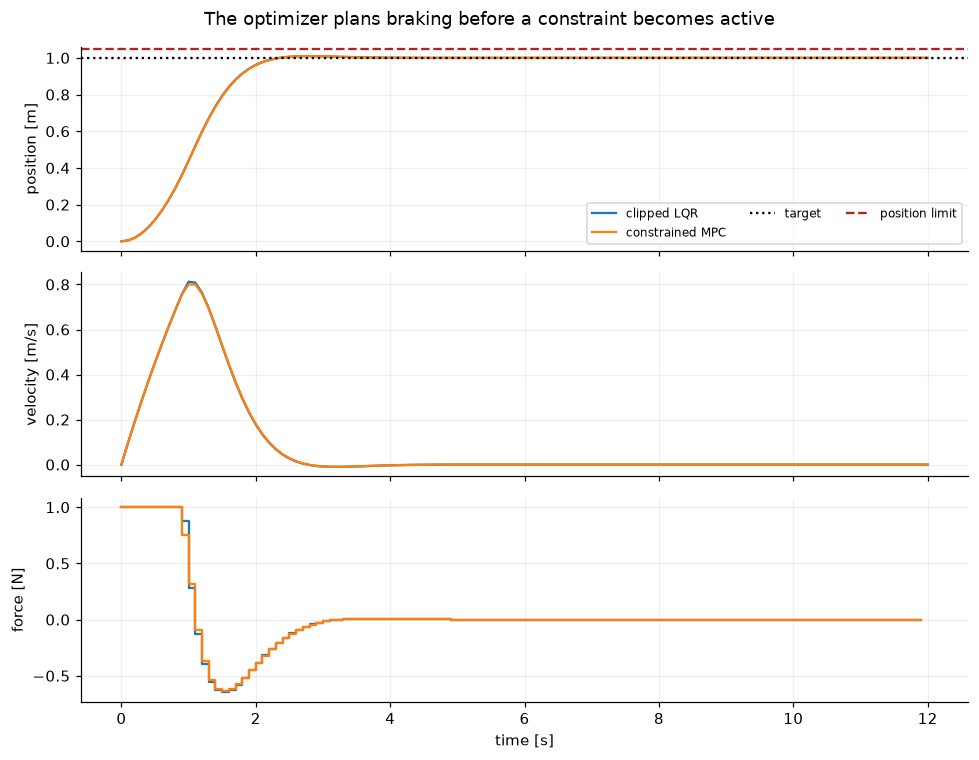

clipped LQR: peak speed=0.812324, peak position=1.009391
MPC: peak speed=0.800000, peak position=1.009282
First solve wall time: 80.45 ms
Subsequent median / max: 2.57 / 22.68 ms; sample period = 100 ms


In [6]:
solve = make_mpc()
plans, timings = {}, []

def mpc_policy(x, k):
    result = solve(x)
    timings.append(result["wall_time"])
    if k in [0, 8, 16]:
        plans[k] = result
    return result["u"]

mpc_run = rollout(mpc_policy)
lqr_run = rollout(lambda x, k: np.clip(-(K@(x-REF)).item(), -1, 1))
plot_runs({"clipped LQR": lqr_run, "constrained MPC": mpc_run},
          "The optimizer plans braking before a constraint becomes active", wall=1.05)
xs, us = mpc_run
assert np.abs(us).max() <= 1.0
assert np.abs(xs[:, 1]).max() <= 0.8+5e-5
assert xs[:, 0].max() <= 1.05+5e-5
assert np.linalg.norm(xs[-1]-REF) < 1e-3
for name, (xx, uu) in {"clipped LQR": lqr_run, "MPC": mpc_run}.items():
    print(f"{name}: peak speed={np.abs(xx[:,1]).max():.6f}, "
          f"peak position={xx[:,0].max():.6f}")
print(f"First solve wall time: {1000*timings[0]:.2f} ms")
print(f"Subsequent median / max: {1000*np.median(timings[1:]):.2f} / "
      f"{1000*np.max(timings[1:]):.2f} ms; sample period = {1000*DT:.0f} ms")


### 从预测轨迹看滚动优化

每条虚线都是某个时刻预测的未来；实线是实际发生的轨迹。默认无扰动、模型一致，二者应高度一致，但有限时域的剩余计划仍可能因为视野重置而调整。第五篇会主动加入扰动，比较一次规划与不断重算。


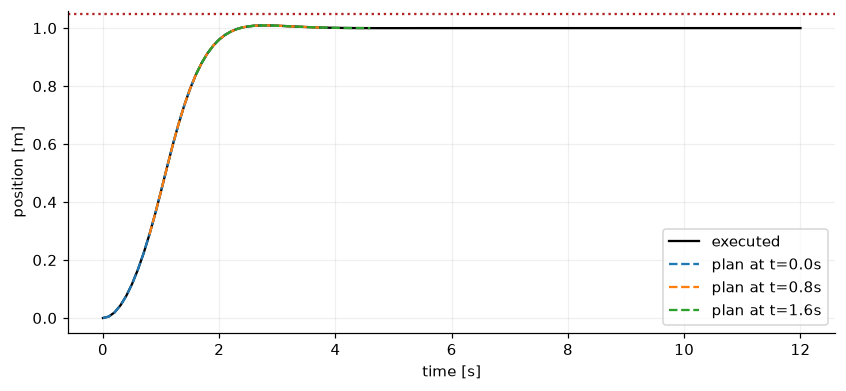

In [7]:
plt.plot(np.arange(len(xs))*DT, xs[:, 0], color="black", label="executed")
for k, plan in plans.items():
    plt.plot((k+np.arange(plan["X"].shape[1]))*DT, plan["X"][0],
             "--", label=f"plan at t={k*DT:.1f}s")
plt.axhline(1.05, color="firebrick", ls=":")
plt.xlabel("time [s]")
plt.ylabel("position [m]")
plt.legend()
plt.show()


## 7. 预测时域与终端设计不是同一旋钮

增加 N 让控制器更早看见将来的约束，但需要更多变量与计算；终端代价描述视野之外的价值。下面固定终端 P，比较从静止出发的最初计划。无约束时它们首步相同，约束激活时视野长度可能改变决策。

默认教学控制器没有终端集合约束。**使用 LQR 终端 P 本身，不足以证明有约束 MPC 的递归可行性或全局稳定性。**

一种标准充分条件路线是：构造终端集合 $\mathcal X_f$，使局部反馈 $u=-Ke$ 在其中保持状态与输入可行，集合对闭环正不变，并满足终端 Lyapunov 下降条件；再加 $e_N\in\mathcal X_f$。这样可以用“旧计划去掉第一步，末尾补局部反馈”的移位论证建立递归可行性。短视野能否到达该终端集，也需要检查。


N=5: u0=1.00000, cold solve=13.9 ms
N=15: u0=1.00000, cold solve=39.6 ms


N=30: u0=1.00000, cold solve=79.7 ms


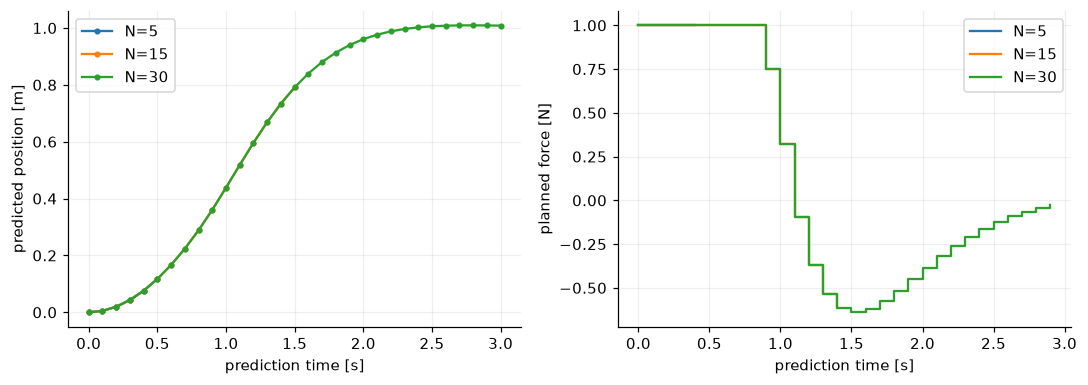

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for horizon in [5, 15, 30]:
    result = make_mpc(horizon)([0, 0])
    axes[0].plot(np.arange(horizon+1)*DT, result["X"][0], marker=".", label=f"N={horizon}")
    axes[1].step(np.arange(horizon)*DT, result["U"], where="post", label=f"N={horizon}")
    print(f"N={horizon}: u0={result['u']:.5f}, cold solve={result['wall_time']*1000:.1f} ms")
axes[0].set_ylabel("predicted position [m]")
axes[1].set_ylabel("planned force [N]")
for ax in axes:
    ax.set_xlabel("prediction time [s]")
    ax.legend()
fig.tight_layout()
plt.show()


## 8. 不可行：优化器不能替物理世界创造刹车距离

考虑初始状态 $p=1.0,v=0.7$。即使用最大反向力，下一采样位置仍将超过 1.05 m。这是物理不可行，不是“求解器没调好”。

我们先直接算最小的一步位置，再求 QP。代码捕获预期的不可行结果并明确展示。真正部署时需要独立的故障响应、可行域监测和经过验证的备用策略；简单返回 u=0 可能反而更危险。


In [9]:
unsafe = np.array([1.0, 0.7])
best_next = A@unsafe-b
print("Next position under maximum braking:", best_next[0])
assert best_next[0] > 1.05
try:
    make_mpc()(unsafe)
except RuntimeError as exc:
    print("Expected failure:", exc)
    assert "infeasible" in str(exc)
else:
    raise AssertionError("This state must be infeasible for the hard problem")


Next position under maximum braking: 1.0636844867814141


Expected failure: MPC status=infeasible; no action was applied


## 9. 软约束让问题可解，不会让越界消失

引入非负松弛 $\epsilon$：

$$p_i\le1.05+\epsilon_{p,i},\quad |v_i|\le0.8+\epsilon_{v,i},\quad\epsilon\ge0.$$

代价增加 $\rho_1\sum\epsilon+\rho_2\|\epsilon\|^2$，尽量减少违反。输入仍是硬约束。软化速度或舒适度约束在工程上很常见；**真实防撞边界不能因为优化问题变成可行就被称为安全**。此处故意软化位置，只用于观察物理上已经无法避免的越界。


First action: -1.0
Max predicted position violation [m]: 0.15697710718041047
Max position slack [m]: 0.15697710647956323


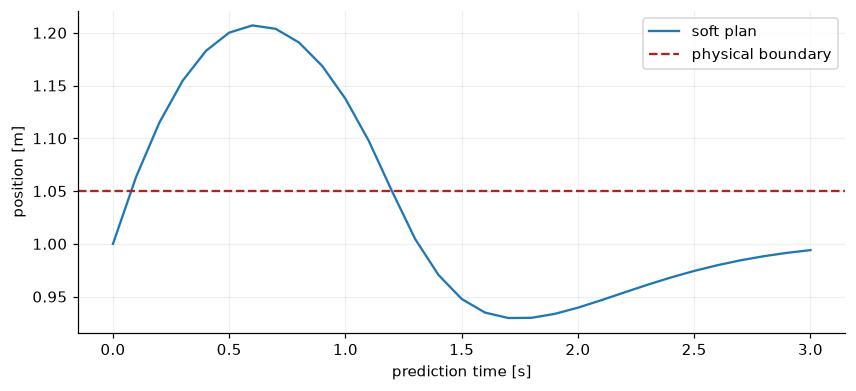

In [10]:
soft_result = make_mpc(soft=True)(unsafe)
predicted = soft_result["X"]
actual_violation = np.maximum(predicted[0, 1:]-1.05, 0)
print("First action:", soft_result["u"])
print("Max predicted position violation [m]:", actual_violation.max())
print("Max position slack [m]:", soft_result["slack"][0].max())
assert actual_violation.max() > 0.01
assert np.all(actual_violation <= soft_result["slack"][0]+5e-5)
plt.plot(np.arange(predicted.shape[1])*DT, predicted[0], label="soft plan")
plt.axhline(1.05, color="firebrick", ls="--", label="physical boundary")
plt.xlabel("prediction time [s]")
plt.ylabel("position [m]")
plt.legend()
plt.show()


## 10. 自测：能解释代码，才算理解 MPC

1. N=30 时，实际会开环执行全部 30 个动作吗？
2. 为什么未来状态约束的循环从 1 到 N，而输入从 0 到 N−1？
3. “优化问题每次有最优解”能否自动推出闭环稳定？
4. $P_f=P$ 什么时候使 MPC 等于 LQR？加入输入界限后还总成立吗？
5. `problem.status` 为 infeasible 时，能否继续使用上一轮 `U.value`？
6. 若目标改到 1.2 m，而硬边界还是 1.05 m，问题一定不可行吗？

<details><summary>参考思路</summary>

1. 只执行第一步。2. 当前状态已知，N 个输入生成 N 个未来状态。3. 不能，还要研究递归可行性、终端条件等。4. 在线性、无约束、同权重与平衡目标条件下成立；约束若激活一般改变解。5. 不能把旧解当成新解，必须进入明确故障路径。6. 未必：本例目标只出现在软代价里，没有终端等式要求到达 1.2，优化器可能停在边界内并留下跟踪误差。

</details>

下一篇把控制器放回相同测试条件，并接上只有位置测量的估计器。
